In [103]:
import numpy as np
import matplotlib.pyplot as plt

In [104]:
def f(t, p):
    a, b = np.polyfit(t, p, 1)
    t_0 = -b / a # p(t) = at + b p(t) gleich 9 setzen => -b /a
    return t_0, a, b


In [105]:
#Eichung der Drucksensors
#die grössen ordnungen sind egal es muss einfach konstant das selbe genommen werden
U_e = np.array([0.5, 4.5])    
p_e = np.array([0.1, 1013.25]) 

_, C, p0 = f(U_e, p_e)

In [106]:
def rho(U):
    return p0 + U * C

In [107]:
t = np.array([0, 100])       # Temperatur [°C]
U = np.array([3.25, 4.25])   # Spannung [V]
p = np.array([rho(U[0]),rho(U[1])])

Beide Grafiken sollten das selbe ergeben


Absoluter Nullpunkt: -325.00000000000017 °C


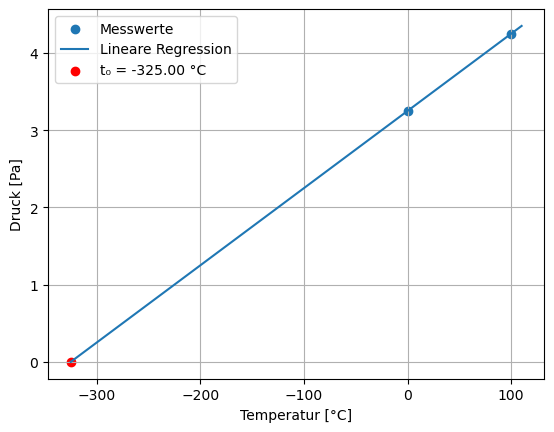

In [108]:
t_0, a, b = f(t, U)

print("Absoluter Nullpunkt:", t_0, "°C")

t_fit = np.linspace(t_0, 110, 200)
p_fit = a * t_fit + b

plt.scatter(t, U, label="Messwerte")
plt.plot(t_fit, p_fit, label="Lineare Regression")
plt.scatter(t_0, 0, color="red", label=f"t₀ = {t_0:.2f} °C")

plt.xlabel("Temperatur [°C]")
plt.ylabel("Druck [Pa]")
plt.legend()
plt.grid()
plt.show()

Absoluter Nullpunkt: -275.0394808271236 °C


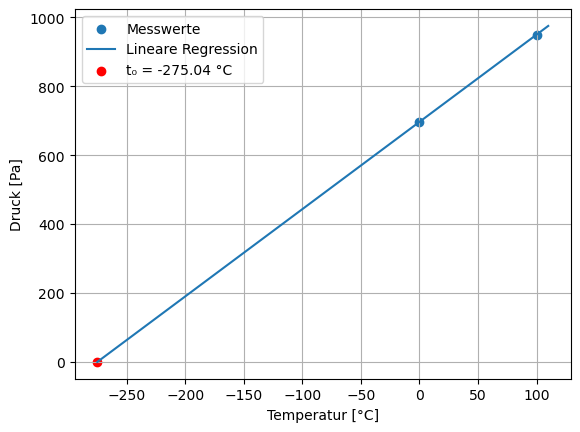

In [109]:

t_0, a, b = f(t, p)

print("Absoluter Nullpunkt:", t_0, "°C")

t_fit = np.linspace(t_0, 110, 200)
p_fit = a * t_fit + b

plt.scatter(t, p, label="Messwerte")
plt.plot(t_fit, p_fit, label="Lineare Regression")
plt.scatter(t_0, 0, color="red", label=f"t₀ = {t_0:.2f} °C")

plt.xlabel("Temperatur [°C]")
plt.ylabel("Druck [Pa]")
plt.legend()
plt.grid()
plt.show()


In [111]:

t_L = 20  # Zimmertemperatur [°C]
t_k = t[1]
t_e = t[0]
p_k = p[1]
p_e = p[0]

epsilon = 1e-3
gamma = 1e-5

a = (1 + epsilon)*p_e - (1 + epsilon + gamma*t_k)*p_k

b = epsilon*(p_k - p_e)*t_k + (1 + gamma*t_k)*p_k*t_L - p_e*(t_L + t_k)

c = p_e*t_L*t_k

t_0_plus = (-b + np.sqrt(b**2 - 4*a*c)) / (2*a)
t_0_minus = (-b - np.sqrt(b**2 - 4*a*c)) / (2*a)

print("t0 (+) =", t_0_plus, "°C")
print("t0 (-) =", t_0_minus, "°C")

t0 (+) = -273.66491283267897 °C
t0 (-) = 20.005422627062398 °C


In [112]:
def t0(p_e, p_k):
    a = (1 + epsilon)*p_e - (1 + epsilon + gamma*t_k)*p_k
    b = epsilon*(p_k - p_e)*t_k + (1 + gamma*t_k)*p_k*t_L - p_e*(t_L + t_k)
    c = p_e*t_L*t_k

    return (-b + np.sqrt(b**2 - 4*a*c)) / (2*a)

In [113]:
h = 0.01  # kleine Druckänderung [mbar]

dt0_dpE = (t0(p_e + h, p_k) - t0(p_e - h, p_k)) / (2*h)
dt0_dpK = (t0(p_e, p_k + h) - t0(p_e, p_k - h)) / (2*h)

print("∂t0/∂pE =", dt0_dpE)
print("∂t0/∂pK =", dt0_dpK)

∂t0/∂pE = -1.4696262017338313
∂t0/∂pK = 1.077767137061869


In [115]:
U_LN2 =  1.27
p_LN2 = rho(U_LN2)

# Erste Gleichung (Näherung)
t_LN2_approx = (1 - p_LN2/p_e) * t_0

# Zweite Gleichung
A = p_e / (t_e - t_0) + epsilon * (p_e - p_LN2) / (t_L - t_0)

t_LN2 = (A*t_0 + p_LN2) / (A - gamma*p_LN2)



print("Temperatur LN2:", t_LN2, "°C")
print("Näherung LN2:", t_LN2_approx, "°C")

print("Abweichung:", abs(t_LN2 - t_LN2_approx), "°C")

Temperatur LN2: -198.20425939024463 °C
Näherung LN2: -198.00000000000014 °C
Abweichung: 0.2042593902444878 °C
